# Which votes needed support from the far right?

In its 10th legislative term, the European Parliament has shifted to the right, and [majorities have become more flexible](https://sieps.se/en/publications/2026/the-centre-is-holding/). The largest group, the European People’s Party (EPP), can form a majority with the Socialists and Democrats (S&D) and Renew Europe (Renew), often called the “von der Leyen coalition”. Alternatively, it can turn right and form a majority with the European Conservatives and Reformists (ECR) and Patriots for Europe (PfE), plus either Renew or Europe of Sovereign Nations (ESN).

In this tutorial, you will learn how to identify votes that only passed because of support from the far-right ECR, PfE, and ESN.

To follow along with the tutorial, you should already be familiar with data analysis in Python using the `pandas` package. You don’t need prior knowledge about the European Parliament.

## Definitions

A political group is required for the majority if it would not have passed if the group’s MEPs that voted for had instead voted against.

For example, consider the following vote result:

| Group | For | Against | Abstentions | Did not vote |
| --- | --- | --- | --- | --- |
| EPP | 94 | 16 | 29 | 45 |
| S&D | 1 | 90 | 0 | 44 |
| PfE | 67 | 0 | 0 | 18 |
| ECR | 72 | 0 | 0 | 12 |
| Renew | 0 | 68 | 0 | 10 |
| Greens/EFA | 0 | 43 | 0 | 10 |
| The Left | 0 | 36 | 0 | 9 |
| Non-attached | 15 | 3 | 3 | 7 |
| ESN | 24 | 0 | 0 | 3 |
| **Total** | **273** | **256** | **32** | **158** |

Assume that this vote needed a majority of the votes cast (sometimes also called a "simple majority"). That is, in order to pass, more MEPs have to vote for than against. MEPs that abstain or do not vote are ignored.

With 273 votes for, and 256 against, this vote would have passed.

Now assume that the 24 ESN MEPs that voted for had instead voted against. The vote wouldn’t have passed with only 273 - 24 = 249 votes for and 256 + 24 = 280 votes against. Thus, the votes by ESN MEPs were required for the majority.

In contrast, had the single S&D MEP that voted for instead voted against, the vote would have still passed with 273 - 1 = 272 votes for and 256 + 1 = 257 votes against. Thus, the vote of the S&D MEP wasn’t required for the majority.

## Data coverage

The HowTheyVote.eu dataset contains data on roll-call votes starting with the 9th legislative term of the European Parliament. To compute the groups required for a majority, we need to know which type of majority is applicable. Many votes in the European Parliament need a majority of votes cast to pass, but in some cases, other majority types apply.

The official data sources we use are missing some information that is necessary to compute the applicable majority type for votes before 2024.

Therefore, we only provide information on the groups that were required for votes starting in 2024 that were cast as part of one of the following procedure types:

* Ordinary Legislative Procedure (COD)
* Own-initiative Procedure (INI)
* Resolutions on topical subjects (RSP)

However, these three procedure types do cover a large part of all adopted roll-call votes since 2024. Let’s load the votes table to examine the exact numbers:

In [1]:
import pandas as pd

# The votes table contains one row per roll-call vote
votes_df = pd.read_csv('data/votes.csv')
votes_df["timestamp"] = pd.to_datetime(votes_df["timestamp"], format="ISO8601")
votes_df.head()

,id,timestamp,display_title,reference,description,amendment_subject,amendment_number,is_main,procedure_reference,procedure_title,procedure_type,procedure_stage,majority_type,count_for,count_against,count_abstention,count_did_not_vote,result,texts_adopted_reference
0,108425,2019-07-15 17:09:37,Mardi - demande du groupe GUE/NGL,NaN,NaN,NaN,NaN,False,NaN,NaN,NaN,NaN,NaN,83,142,72,454,NaN,NaN
1,108530,2019-07-18 11:30:02,The situation in Venezuela,RC-B9-0006/2019,§ 2/1,NaN,NaN,False,2019/2730(RSP),The situation in Venezuela,RSP,NaN,MAJORITY_OF_VOTES_CAST,506,58,70,117,NaN,P9_TA(2019)0007
2,108531,2019-07-18 11:30:16,The situation in Venezuela,RC-B9-0006/2019,§ 2/2,NaN,NaN,False,2019/2730(RSP),The situation in Venezuela,RSP,NaN,MAJORITY_OF_VOTES_CAST,414,184,51,102,NaN,P9_TA(2019)0007
3,108532,2019-07-18 11:30:30,The situation in Venezuela,RC-B9-0006/2019,Résolution,NaN,NaN,True,2019/2730(RSP),The situation in Venezuela,RSP,NaN,MAJORITY_OF_VOTES_CAST,455,85,105,106,NaN,P9_TA(2019)0007
4,108533,2019-07-18 11:24:18,The situation at the USA-Mexican border,RC-B9-0014/2019,§ 13,NaN,NaN,False,2019/2733(RSP),The situation at the USA-Mexican border,RSP,NaN,MAJORITY_OF_VOTES_CAST,311,269,33,138,NaN,P9_TA(2019)0005


In [2]:
# We are interested only in adopted votes from 2024 onwarwd
votes_df = votes_df[
    (votes_df["timestamp"] >= "2024-01-01") &
    (votes_df["result"] == "ADOPTED")
].copy()

share = votes_df["majority_type"].notna().mean() * 100
print(f"{share:.1f}% of adopted votes since 2024 have a known majority type")

80.3% of adopted votes since 2024 have a known majority type


Let’s take a closer look and plot the number of votes with a majority type out of all votes by month.

Matplotlib is building the font cache; this may take a moment.


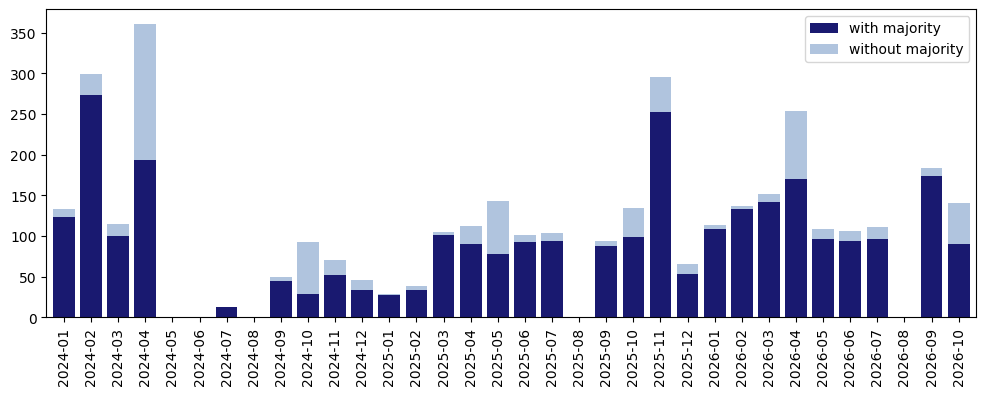

In [3]:
import matplotlib.pyplot as plt

# Add month as a new column
votes_df["month"] =  votes_df["timestamp"].dt.to_period("M")

# Filter votes with and without majority type
with_majority_df = votes_df[votes_df["majority_type"].notna()]
without_majority_df = votes_df[votes_df["majority_type"].isna()]

# Count by month
chart_df = pd.DataFrame({
    "with majority": with_majority_df.groupby("month").size(),
    "without majority": without_majority_df.groupby("month").size(),
})

# Fill months with no votes with 0 (for example plenary summer break in August)
chart_df = chart_df.reindex(
    pd.period_range(
        chart_df.index.min(),
        chart_df.index.max(),
        freq="M",
    ),
    fill_value=0,
)

# Plot
chart_df.plot(
    kind="bar",
    stacked=True,
    figsize=(12, 4),
    color=["midnightblue", "lightsteelblue"],
    width=0.8,
)

plt.show()

## Which votes needed support from PfE?

We start with a single group. Which votes required support from Patriots for Europe (PfE)?

The dataset already contains information about the required groups, so we don’t have to compute it ourselves. Load the information from the separate `groups_required_for_majority.csv` table:

In [4]:
groups_required_df = pd.read_csv("data/groups_required_for_majority.csv")
groups_required_df.head()

,vote_id,group_codes
0,162202,EPP+GREEN_EFA
1,162202,EPP+RENEW
2,162202,EPP+SD
3,162202,GREEN_EFA+RENEW
4,162202,GREEN_EFA+SD


Every row represents a combination of political groups (`group_codes`) that were required for a single vote (`vote_id`) to pass.

A single group code means that that group was required for the majority. For example, `PFE` means that the vote would not have passed if all PfE MEPs that voted for had instead voted against.

Multiple group codes mean that these groups together were required for the majority. For example, `ECR+PFE` means that the vote would not have passed if all ECR MEPs *and* all PfE MEPs that voted for had instead voted against. However, if *only*  the `ECR` MEPs that voted for had instead voted against, the vote would have still passed.

To find votes where PfE alone was required, filter for `PFE` in the `group_codes` column:

In [5]:
required_pfe_df = groups_required_df[groups_required_df["group_codes"] == "PFE"]
count = required_pfe_df["vote_id"].nunique()
print(f"{count} votes required support from PfE")

214 votes required support from PfE


Again, we can also look at these numbers over time:

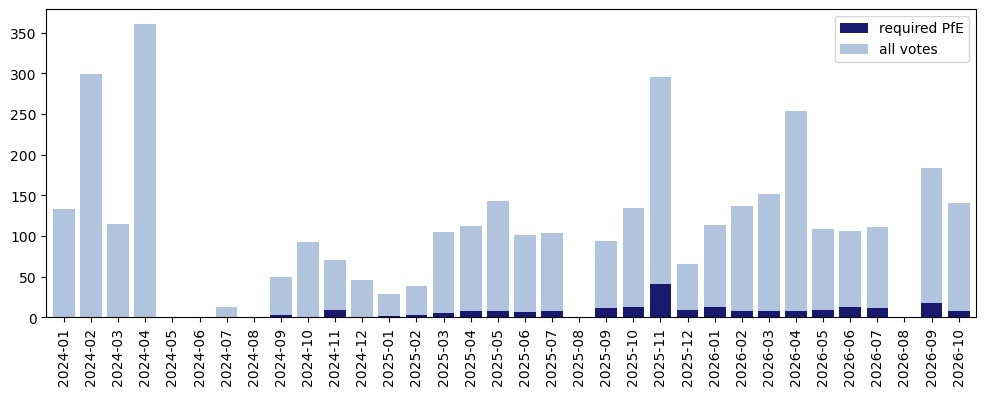

In [6]:
mask = votes_df["id"].isin(required_pfe_df["vote_id"])

chart_df = pd.DataFrame({
    "required PfE": votes_df[mask].groupby("month").size(),
    "all votes": votes_df[~mask].groupby("month").size(),
})

chart_df = chart_df.reindex(
    pd.period_range(chart_df.index.min(), chart_df.index.max(), freq="M"),
    fill_value=0,
)

chart_df.plot(kind="bar", stacked=True, figsize=(12, 4), color=["midnightblue", "lightsteelblue"], width=0.8)

plt.show()

## Which votes needed support from far-right groups?

Before, we looked at votes which needed one of the far-right groups, the PfE. Now we look at the far-right groups (ECR, PfE, and ESN) together? We want to find votes that would not have passed if the MEPs from one or more of these groups had voted against.

The dataset only lists minimal combinations of groups. For example, if ECR alone is required, that implies that any larger combination (for example ECR and PfE together) is also required, but it isn’t listed.

As we want to find votes that needed support from one or more of the three far-right groups, that means we’ll have to filter for the following values in the `group_codes` column:

1. `ECR`
2. `ESN`
3. `PFE`
4. `ECR+ESN`
5. `ECR+PFE`
6. `ESN+PFE`
7. `ECR+ESN+PFE`

In [7]:
combinations = [
    "ECR",
    "ESN",
    "PFE",
    "ECR+ESN",
    "ECR+PFE",
    "ESN+PFE",
    "ECR+ESN+PFE",
]

required_far_right_df = groups_required_df[groups_required_df["group_codes"].isin(combinations)]
count = required_far_right_df["vote_id"].nunique()
print(f"{count} votes required support from the far right")

446 votes required support from the far right


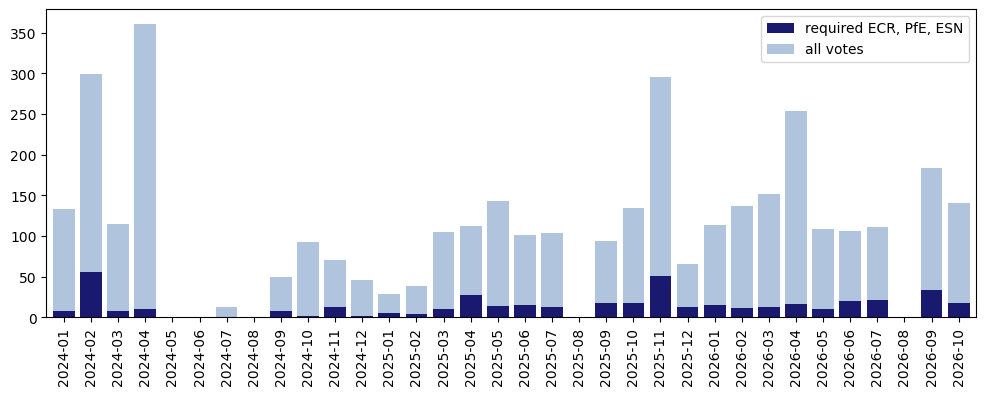

In [8]:
mask = votes_df["id"].isin(required_far_right_df["vote_id"])

chart_df = pd.DataFrame({
    "required ECR, PfE, ESN": votes_df[mask].groupby("month").size(),
    "all votes": votes_df[~mask].groupby("month").size(),
})

chart_df = chart_df.reindex(
    pd.period_range(chart_df.index.min(), chart_df.index.max(), freq="M"),
    fill_value=0,
)

chart_df.plot(kind="bar", stacked=True, figsize=(12, 4), color=["midnightblue", "lightsteelblue"], width=0.8)

plt.show()